# 01 · Contextualização do problema e limpeza dos dados

**Disciplina:** SISB110 — Ciência dos Dados e Inteligência Empresarial (UFAL · Unidade Penedo)
**Aluno:** José Gabriel Fideles Silva · **Docente:** Jário José

Este notebook cobre a **Etapa I** (contexto e perguntas de negócio) e a primeira parte da **Etapa II** (limpeza e qualidade) do roteiro.

| Notebook | Conteúdo |
|---|---|
| **01 (este)** | Contexto, perguntas, qualidade dos dados, limpeza e tipagem |
| 02 | Estatística descritiva, gráficos e correlação |
| 03 | Intervalos de confiança e testes de hipóteses |

## Etapa I — Contextualização e formulação do problema

### Domínio e origem dos dados
A **rotatividade de funcionários** (*attrition*) é um dos principais problemas de Gestão de Pessoas: cada desligamento gera custos de recrutamento, seleção e treinamento do substituto, além da perda de conhecimento e produtividade.

O dataset **IBM HR Analytics Employee Attrition & Performance** foi criado por cientistas de dados da IBM e publicado no Kaggle:
<https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset/data>

> ⚠️ **Os dados são fictícios** (simulados para fins didáticos). As conclusões ilustram o método e não descrevem uma empresa real.

### Objetivo geral
> **Identificar os fatores salariais, de envolvimento e de ambiente de trabalho associados à rotatividade de funcionários, para subsidiar ações de retenção priorizadas por evidência estatística.**

### Perguntas de negócio
| # | Pergunta | Procedimento inferencial |
|---|---|---|
| **Q1** | Qual é a taxa de rotatividade e ela difere entre departamentos? | IC 95% da proporção + Qui-Quadrado |
| **Q2** | Funcionários que saem ganham menos do que os que ficam? | Teste t + IC 95% da diferença de médias |
| **Q3** | Envolvimento, ambiente, satisfação e equilíbrio vida-trabalho estão associados à saída? | Qui-Quadrado (×4, correção de Holm) |
| **Q4** | Fazer hora extra está associado a mais saídas? | Qui-Quadrado 2×2 + IC 95% da diferença de proporções |
| **Q5** | O desempenho e o envolvimento se refletem no reajuste salarial? | Teste t + ANOVA + Teste de Correlação |

In [1]:
# ---------------------------------------------------------------
# Configuração do ambiente
# ---------------------------------------------------------------
# Localiza a raiz do projeto (pasta que contém "src/") para que os imports
# funcionem tanto rodando o notebook pelo Jupyter quanto pelo run_all.py.
import sys
from pathlib import Path

raiz = Path.cwd()
while not (raiz / "src").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import config
from src import limpeza, descritiva, inferencia, graficos

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
graficos.aplicar_estilo()

## 1. Carregamento dos dados brutos
O arquivo original fica em `data/raw/` e **nunca é alterado**. Toda transformação gera um novo arquivo em `data/processed/`.

In [2]:
bruto = limpeza.carregar_dados_brutos()
print(f"Linhas: {bruto.shape[0]:,} · Colunas: {bruto.shape[1]}".replace(",", "."))
bruto.head()

Linhas: 1.470 · Colunas: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


### Requisitos do roteiro
O roteiro exige **≥ 500 registros**, **≥ 5 variáveis numéricas** e **≥ 3 categóricas**. A contagem abaixo usa a tipagem estatística definida em `src/config.py`, e não o tipo lido pelo pandas (as escalas 1–4, por exemplo, são lidas como números, mas são categorias ordinais).

In [3]:
n_num = len(config.VARS_NUMERICAS)
n_cat = len(config.VARS_CATEGORICAS)
print(f"Registros: {len(bruto)}  (mínimo 500)   → {'OK' if len(bruto) >= 500 else 'FALHA'}")
print(f"Numéricas: {n_num}     (mínimo 5)     → {'OK' if n_num >= 5 else 'FALHA'}")
print(f"Categóricas: {n_cat}   (mínimo 3)     → {'OK' if n_cat >= 3 else 'FALHA'}")

Registros: 1470  (mínimo 500)   → OK
Numéricas: 11     (mínimo 5)     → OK
Categóricas: 17   (mínimo 3)     → OK


## 2. Diagnóstico de qualidade

### 2.1 Valores ausentes e tipos lidos

In [4]:
qualidade = limpeza.relatorio_qualidade(bruto)
print(f"Total de valores ausentes na base: {int(qualidade['ausentes'].sum())}")
qualidade

Total de valores ausentes na base: 0


,tipo_pandas,ausentes,pct_ausentes,valores_distintos
Age,int64,0,0.00,43
Attrition,str,0,0.00,2
BusinessTravel,str,0,0.00,3
DailyRate,int64,0,0.00,886
Department,str,0,0.00,3
DistanceFromHome,int64,0,0.00,29
Education,int64,0,0.00,5
EducationField,str,0,0.00,6
EmployeeCount,int64,0,0.00,1
EmployeeNumber,int64,0,0.00,1470


**Decisão:** não há valores ausentes em nenhuma das 35 colunas. **Nenhuma imputação ou exclusão é necessária.**

### 2.2 Duplicatas
Verificamos linhas inteiramente repetidas e se o identificador `EmployeeNumber` se repete.

In [5]:
dup = limpeza.verificar_duplicatas(bruto)
dup

{'linhas_duplicadas': 0, 'ids_duplicados': 0}

**Decisão:** não há duplicatas: cada linha é um funcionário distinto. Isso também garante a **independência das observações**, um pressuposto de todos os testes da Etapa III.

### 2.3 Colunas constantes

In [6]:
constantes = limpeza.encontrar_colunas_constantes(bruto)
bruto[constantes].drop_duplicates()

,EmployeeCount,Over18,StandardHours
0,1,Y,80


**Decisão:** `EmployeeCount` (sempre 1), `Over18` (sempre "Y") e `StandardHours` (sempre 80) têm um único valor, então não diferenciam ninguém. **Serão removidas.**

### 2.4 Colunas de "taxa" (DailyRate, HourlyRate, MonthlyRate)
Se essas colunas medissem a remuneração, deveriam se correlacionar fortemente com a renda mensal (`MonthlyIncome`).

In [7]:
bruto[config.COLUNAS_TAXA_INCONSISTENTES].corrwith(bruto["MonthlyIncome"]).to_frame("correlação com MonthlyIncome")

,correlação com MonthlyIncome
DailyRate,0.01
HourlyRate,-0.02
MonthlyRate,0.03


**Decisão:** as correlações são praticamente zero, ou seja, as colunas não são coerentes com a renda (é uma inconsistência conhecida desta base simulada). Elas **são mantidas no arquivo**, mas **ficam fora das análises**. A medida salarial usada é `MonthlyIncome`.

### 2.5 Outliers (regra do IQR)
Um valor é considerado outlier se estiver abaixo de **Q1 − 1,5·IQR** ou acima de **Q3 + 1,5·IQR**.

In [8]:
outliers = limpeza.detectar_outliers_iqr(bruto, config.VARS_NUMERICAS)
descritiva.salvar_tabela(outliers.round(2), "outliers_iqr")
outliers

,Q1,Q3,IQR,limite_inferior,limite_superior,n_outliers,pct_outliers,maximo_observado
variavel,,,,,,,,
Age,30.00,43.00,13.00,10.50,62.50,0,0.00,60
MonthlyIncome,"2,911.00","8,379.00","5,468.00","-5,291.00","16,581.00",114,7.76,19999
DistanceFromHome,2.00,14.00,12.00,-16.00,32.00,0,0.00,29
NumCompaniesWorked,1.00,4.00,3.00,-3.50,8.50,52,3.54,9
PercentSalaryHike,12.00,18.00,6.00,3.00,27.00,0,0.00,25
TotalWorkingYears,6.00,15.00,9.00,-7.50,28.50,63,4.29,40
TrainingTimesLastYear,2.00,3.00,1.00,0.50,4.50,238,16.19,6
YearsAtCompany,3.00,9.00,6.00,-6.00,18.00,104,7.07,40
YearsInCurrentRole,2.00,7.00,5.00,-5.50,14.50,21,1.43,18


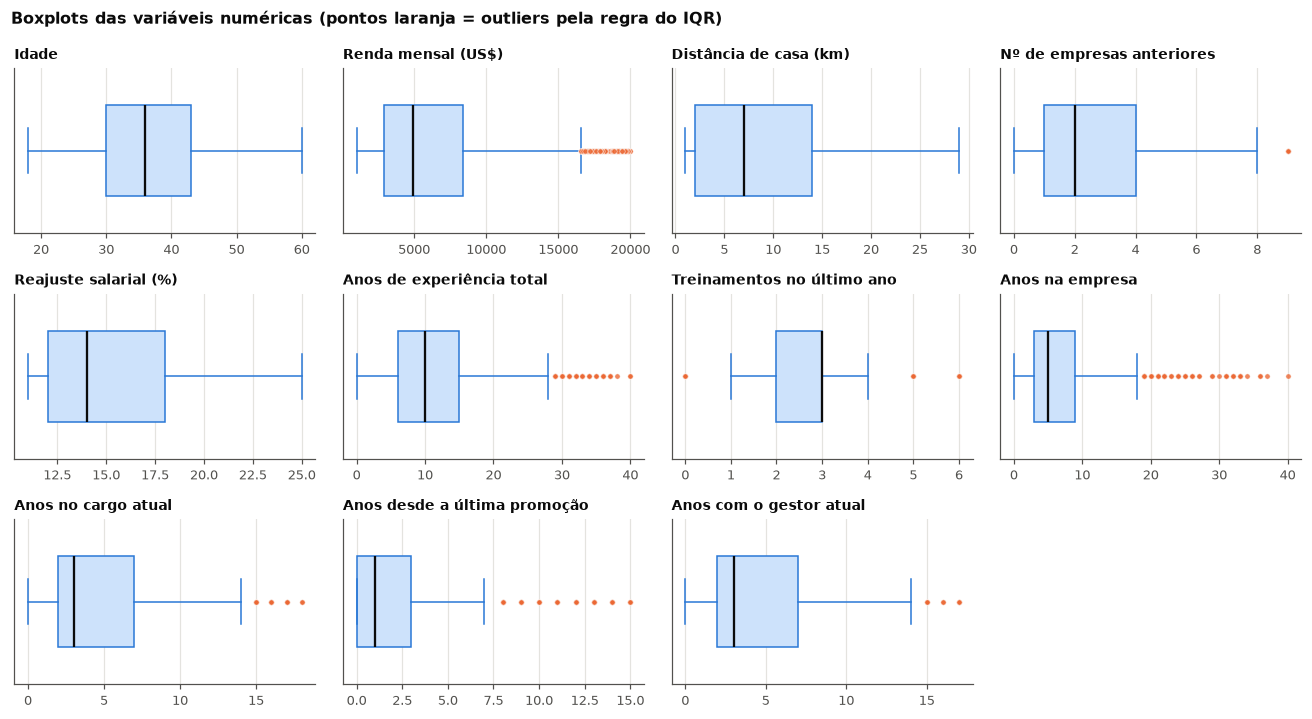

In [9]:
fig = graficos.grade_boxplots(bruto, config.VARS_NUMERICAS, ncols=4)
fig.suptitle("Boxplots das variáveis numéricas (pontos laranja = outliers pela regra do IQR)",
             x=0.01, ha="left", fontsize=10.5, weight="bold", y=1.03)
graficos.salvar(fig, "fig02_outliers_boxplots")
plt.show()

**Decisão: manter os outliers.**

- Os valores extremos são **plausíveis e legítimos**: rendas altas (até US$ 19.999) pertencem a cargos de nível 4–5 (diretores e gerentes); muitos anos de casa ou de experiência correspondem a funcionários antigos; em `TrainingTimesLastYear`, 0 ou 5–6 treinamentos são valores possíveis.
- Removê-los **distorceria a análise**: tiraríamos justamente os funcionários sêniores, que são parte importante do perfil de quem fica.
- O efeito deles nos testes é tratado na Etapa III (pressupostos, versão de Welch, correlação de Spearman e verificação com escala logarítmica).

💡 **Insight:** `MonthlyIncome` tem 114 outliers (7,8%), todos acima de ~US$ 16,6 mil. A renda é **assimétrica à direita**: muitos salários baixos e poucos muito altos. Por isso a **mediana** descreve o "salário típico" melhor do que a média.

## 3. Limpeza, tipagem e variáveis derivadas
A função `limpeza.limpar_dados` aplica todas as decisões acima e cria:
- `Attrition_bin` e `OverTime_bin` (0/1): a **média de uma variável 0/1 é uma proporção**, o que facilita calcular taxas;
- rótulos em português das escalas ordinais (`*_rot`), por exemplo `JobInvolvement` 1 → "Baixo";
- faixas de idade, salário (quartis) e tempo de casa, para leitura de negócio.

In [10]:
limpo = limpeza.aplicar_tipos(limpeza.limpar_dados(bruto))
print(f"Antes: {bruto.shape} · Depois: {limpo.shape}")
print(f"Linhas preservadas: {len(limpo) == len(bruto)}")
print(f"Colunas removidas: {sorted(set(bruto.columns) - set(limpo.columns))}")
limpo[["Attrition", "Attrition_bin", "Status", "JobInvolvement", "JobInvolvement_rot",
       "MonthlyIncome", "FaixaSalarial", "Age", "FaixaEtaria"]].head()

Antes: (1470, 35) · Depois: (1470, 49)
Linhas preservadas: True
Colunas removidas: ['EmployeeCount', 'Over18', 'StandardHours']


,Attrition,Attrition_bin,Status,JobInvolvement,JobInvolvement_rot,MonthlyIncome,FaixaSalarial,Age,FaixaEtaria
0,Yes,1,Saiu,3,Alto,5993,Q3,41,36–45
1,No,0,Ficou,2,Médio,5130,Q3,49,46–60
2,Yes,1,Saiu,2,Médio,2090,Q1 (mais baixa),37,36–45
3,No,0,Ficou,3,Alto,2909,Q1 (mais baixa),33,26–35
4,No,0,Ficou,3,Alto,3468,Q2,27,26–35


### 3.1 Tipagem estatística das variáveis
O tipo **estatístico** define quais medidas e testes podem ser usados: média e teste t só fazem sentido para quantitativas, e frequências e Qui-Quadrado para qualitativas.

| Tipo | Significado |
|---|---|
| Quantitativa contínua | Medida que pode assumir qualquer valor num intervalo |
| Quantitativa discreta | Contagem (anos, nº de empresas, %) |
| Qualitativa nominal | Categoria sem ordem (departamento, gênero) |
| Qualitativa ordinal | Categoria com ordem (escalas de 1 a 4, nível do cargo) |

In [11]:
tipagem = pd.DataFrame(
    [(var, tipo, config.NOMES_PT.get(var, var), str(bruto[var].dtype))
     for tipo, variaveis in config.TIPOS_VARIAVEIS.items() for var in variaveis],
    columns=["variavel", "tipo_estatistico", "descricao", "tipo_lido_pandas"],
)
descritiva.salvar_tabela(tipagem, "tipagem_variaveis", index=False)
tipagem

,variavel,tipo_estatistico,descricao,tipo_lido_pandas
0,Age,Quantitativa contínua,Idade,int64
1,MonthlyIncome,Quantitativa contínua,Renda mensal (US$),int64
2,DistanceFromHome,Quantitativa discreta,Distância de casa (km),int64
3,NumCompaniesWorked,Quantitativa discreta,Nº de empresas anteriores,int64
4,PercentSalaryHike,Quantitativa discreta,Reajuste salarial (%),int64
5,TotalWorkingYears,Quantitativa discreta,Anos de experiência total,int64
6,TrainingTimesLastYear,Quantitativa discreta,Treinamentos no último ano,int64
7,YearsAtCompany,Quantitativa discreta,Anos na empresa,int64
8,YearsInCurrentRole,Quantitativa discreta,Anos no cargo atual,int64
9,YearsSinceLastPromotion,Quantitativa discreta,Anos desde a última promoção,int64


### 3.2 Registro das decisões de limpeza
Esta tabela vai para a seção de Metodologia do relatório.

In [12]:
decisoes = pd.DataFrame([
    ("Valores ausentes", f"{int(qualidade['ausentes'].sum())} em 35 colunas", "Nenhuma ação", "Base completa"),
    ("Duplicatas", f"{dup['linhas_duplicadas']} linhas · {dup['ids_duplicados']} IDs", "Nenhuma ação", "Cada linha é um funcionário único"),
    ("Colunas constantes", ", ".join(constantes), "Removidas", "Variância zero, sem informação"),
    ("Identificador", "EmployeeNumber", "Mantido só como ID", "Não é variável analítica"),
    ("Taxas inconsistentes", "DailyRate, HourlyRate, MonthlyRate", "Mantidas, fora da análise", "Correlação ≈ 0 com MonthlyIncome"),
    ("Outliers (IQR)", f"{int(outliers['n_outliers'].sum())} valores em {int((outliers['n_outliers'] > 0).sum())} variáveis", "Mantidos", "Valores legítimos (cargos sêniores); testes robustos na Etapa III"),
    ("Escalas 1–4 / 1–5", "Satisfação, envolvimento, escolaridade...", "Convertidas em ordinais rotuladas", "São categorias ordenadas, não medidas"),
    ("Variáveis derivadas", "Attrition_bin, OverTime_bin, faixas", "Criadas", "Facilitar taxas e leitura de negócio"),
], columns=["verificacao", "resultado", "acao", "justificativa"])
descritiva.salvar_tabela(decisoes, "decisoes_limpeza", index=False)
decisoes

,verificacao,resultado,acao,justificativa
0,Valores ausentes,0 em 35 colunas,Nenhuma ação,Base completa
1,Duplicatas,0 linhas · 0 IDs,Nenhuma ação,Cada linha é um funcionário único
2,Colunas constantes,"EmployeeCount, Over18, StandardHours",Removidas,"Variância zero, sem informação"
3,Identificador,EmployeeNumber,Mantido só como ID,Não é variável analítica
4,Taxas inconsistentes,"DailyRate, HourlyRate, MonthlyRate","Mantidas, fora da análise",Correlação ≈ 0 com MonthlyIncome
5,Outliers (IQR),713 valores em 8 variáveis,Mantidos,Valores legítimos (cargos sêniores); testes ro...
6,Escalas 1–4 / 1–5,"Satisfação, envolvimento, escolaridade...",Convertidas em ordinais rotuladas,"São categorias ordenadas, não medidas"
7,Variáveis derivadas,"Attrition_bin, OverTime_bin, faixas",Criadas,Facilitar taxas e leitura de negócio


## 4. Salvando a base limpa

In [13]:
limpeza.salvar_dados_limpos(limpo)
print(f"Base limpa salva em: {config.DADOS_LIMPOS.relative_to(config.RAIZ)}")

Base limpa salva em: data/processed/hr_attrition_limpo.csv


## 5. Fluxo metodológico do projeto

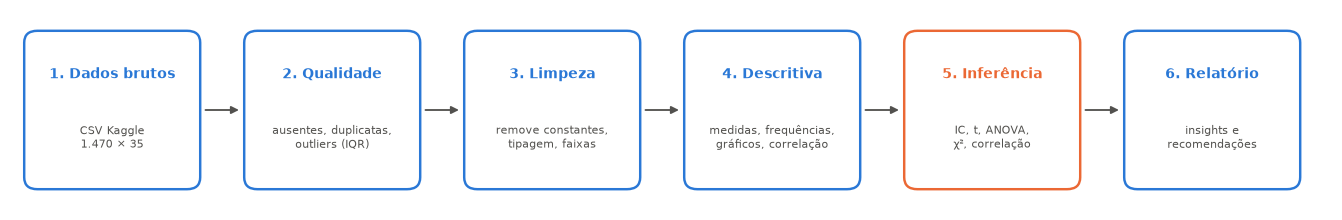

In [14]:
fig = graficos.fluxo_pipeline()
graficos.salvar(fig, "fig01_fluxo_metodologia")
plt.show()

## Resumo do notebook 01
- A base tem **1.470 funcionários e 35 colunas**, **sem ausentes e sem duplicatas**.
- Foram removidas **3 colunas constantes**; as 3 colunas de "taxa" ficam fora da análise por inconsistência.
- **Os outliers foram mantidos** por serem legítimos; o efeito deles é controlado nos testes.
- A base limpa (`data/processed/hr_attrition_limpo.csv`) é o ponto de partida dos notebooks 02 e 03.